In [1]:
"""
preprocessing.py

Cleans raw genomic sequences, handles variable lengths,
and prepares train/test splits for the multimodal fusion project.

Key challenges specific to genomic sequences:
  1. Variable length: coronavirus ~30,000 nt vs influenza ~2,200 nt
  2. Ambiguous characters: N, R, Y, etc. (not pure ACGT)
  3. Class imbalance across 30 virus types
  4. No natural "window" like ECG beats — we must define one
"""

import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:

# ── Constants ────────────────────────────────────────────────────
VALID_NUCLEOTIDES = set("ACGT")

# This is the core design decision for variable-length handling.
# We slice each sequence into non-overlapping windows of this size.
# Reasoning:
#   - Must be divisible by 3 (codon-aligned for PageRank features)
#   - Long enough to capture meaningful Markov statistics
#   - Short enough that even short influenza segments (~2200 nt)
#     yield at least 1 window
#   - 2100 = 700 codons — well within influenza segment lengths
#     and gives ~14 windows per coronavirus genome
WINDOW_SIZE = 2100   # nucleotides per window, divisible by 3

PROCESSED_DIR = Path("C:\\Users\\rodri\\Desktop\\MASTER\\EMMBIOME\\Grecia\\Courses\\Bioinformatics\\Project\\genomic_multimodal_fusion\\data\\processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


In [3]:


# ════════════════════════════════════════════════════════════════
# STEP 1 — SEQUENCE CLEANING
# ════════════════════════════════════════════════════════════════

def clean_sequence(seq: str) -> str:
    """
    Cleans a raw nucleotide sequence.

    Operations:
      - Uppercase
      - Remove whitespace and digits (sometimes present in FASTA)
      - Remove ambiguous IUPAC characters (N, R, Y, S, W, K, M,
        B, D, H, V) — keeping only unambiguous A, C, G, T

    Why remove ambiguous characters?
      Our feature extraction (CPNR encoding, Markov transitions)
      requires a known nucleotide at each position. Ambiguous
      characters like N (= any nucleotide) would introduce noise
      into the transition probability matrix. Removing them is
      standard practice for signal-processing approaches to DNA.

    Note: This may shorten sequences slightly. We check minimum
    length after cleaning.
    """
    seq = seq.upper().strip()
    # Remove anything that is not A, C, G, T
    seq = "".join(c for c in seq if c in VALID_NUCLEOTIDES)
    return seq


def clean_dataframe(df: pd.DataFrame, min_length: int = 500) -> pd.DataFrame:
    """
    Applies cleaning to all sequences in the DataFrame.
    Drops sequences that are too short after cleaning.

    Parameters
    ----------
    df         : DataFrame with a 'sequence' column
    min_length : minimum acceptable length after cleaning

    Returns
    -------
    Cleaned DataFrame with updated 'length' column
    """
    print(f"Cleaning {len(df)} sequences...")
    original_count = len(df)

    df = df.copy()
    df["sequence"] = df["sequence"].apply(clean_sequence)
    df["length"]   = df["sequence"].str.len()

    # Drop sequences that are too short after cleaning
    df = df[df["length"] >= min_length].reset_index(drop=True)

    dropped = original_count - len(df)
    if dropped > 0:
        print(f"  Dropped {dropped} sequences shorter than {min_length} nt")
    print(f"  Kept {len(df)} sequences")

    return df


In [4]:


# ════════════════════════════════════════════════════════════════
# STEP 2 — VARIABLE LENGTH HANDLING
# ════════════════════════════════════════════════════════════════
#
# This is the most important design decision in preprocessing.
# Unlike ECG beats (which are naturally segmented between R-peaks),
# genomic sequences have no natural fixed-length unit.
#
# Three common strategies exist:
#
#   A) TRUNCATE / PAD to a fixed length
#      Pro: Simple, preserves one record per sequence
#      Con: Truncation discards information; padding adds fake data
#
#   B) SLIDING WINDOW — extract overlapping or non-overlapping
#      windows of fixed length from each sequence
#      Pro: Makes full use of all data, naturally augments dataset
#      Con: Windows from the same sequence are not independent
#           (must be careful not to let them leak across train/test)
#
#   C) FIXED-SIZE FEATURE VECTOR regardless of length
#      (e.g. PageRank always gives 64 values regardless of length)
#      Pro: No windowing needed for some feature types
#      Con: Very short sequences give unreliable statistics
#
# We use strategy B (sliding window) because:
#   - It maximizes use of long coronavirus sequences
#   - It is compatible with all three feature streams
#   - We apply the train/test split BEFORE windowing to prevent
#     data leakage (see split_sequences below)

def extract_windows(
    sequence: str,
    window_size: int = WINDOW_SIZE,
    step: int = None,
    codon_aligned: bool = True,
) -> list:
    """
    Extracts fixed-length non-overlapping windows from a sequence.

    Parameters
    ----------
    sequence      : cleaned nucleotide string
    window_size   : length of each window (should be divisible by 3)
    step          : step between windows (default = window_size,
                    i.e. non-overlapping)
    codon_aligned : if True, windows start at codon boundaries
                    (positions 0, 3, 6, ...) ensuring no codon
                    is split across windows

    Returns
    -------
    List of window strings. Empty list if sequence < window_size.

    Why codon_aligned?
      Codons are the biological unit for PageRank feature Stream B.
      If a window starts mid-codon, the first triplet is meaningless.
      Aligning to codon boundaries ensures every triplet in every
      window is a valid codon context.
    """
    if step is None:
        step = window_size

    # Codon alignment: ensure step is also divisible by 3
    if codon_aligned:
        window_size = (window_size // 3) * 3
        step        = (step // 3) * 3

    windows = []
    for start in range(0, len(sequence) - window_size + 1, step):
        window = sequence[start : start + window_size]
        if len(window) == window_size:
            windows.append(window)

    return windows


def window_dataframe(
    df: pd.DataFrame,
    window_size: int = WINDOW_SIZE,
    step: int = None,
) -> pd.DataFrame:
    """
    Applies sliding window extraction to the entire DataFrame.
    Each window becomes a separate row, inheriting the virus
    label from its parent sequence.

    The 'source_accession' column tracks which original sequence
    each window came from — critical for preventing data leakage
    during train/test splitting.
    """
    print(f"\nExtracting windows (size={window_size}) ...")
    rows = []

    for _, row in df.iterrows():
        windows = extract_windows(
            row["sequence"],
            window_size=window_size,
            step=step,
        )
        for i, w in enumerate(windows):
            rows.append({
                "source_accession" : row["accession"],
                "window_id"        : i,
                "sequence"         : w,
                "length"           : len(w),
                "virus"            : row["virus"],
                "label"            : row["label"],
            })

    df_windows = pd.DataFrame(rows)

    print(f"  Generated {len(df_windows)} windows from "
          f"{len(df)} sequences")
    print(f"\n  Windows per virus:")
    print(df_windows.groupby("virus")["window_id"]
          .count().to_string())

    return df_windows



In [5]:

# ════════════════════════════════════════════════════════════════
# STEP 3 — TRAIN/TEST SPLIT
# ════════════════════════════════════════════════════════════════
#
# CRITICAL: The split must happen at the SEQUENCE level,
# not the WINDOW level.
#
# If you split at the window level, windows from the same
# original sequence can appear in both train and test sets.
# Since windows from the same sequence are highly similar
# (they come from the same genome), this inflates accuracy
# by up to 15-20% — a form of data leakage.
#
# Correct procedure:
#   1. Split unique accession numbers into train/test
#   2. Extract windows
#   3. Assign windows to train/test based on their source accession

def split_sequences(
    df: pd.DataFrame,
    test_size: float = 0.2,
    random_state: int = 42,
    stratify: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Splits the sequence-level DataFrame into train and test sets
    BEFORE windowing, stratified by virus label.

    Parameters
    ----------
    df           : sequence-level DataFrame (not windowed)
    test_size    : fraction of sequences for test set
    random_state : for reproducibility
    stratify     : if True, preserves class proportions in split

    Returns
    -------
    (df_train, df_test) — sequence-level DataFrames
    """
    print(f"\nSplitting {len(df)} sequences "
          f"({int((1-test_size)*100)}/{int(test_size*100)} train/test) ...")

    stratify_col = df["label"] if stratify else None

    df_train, df_test = train_test_split(
        df,
        test_size=test_size,
        random_state=random_state,
        stratify=stratify_col,
    )

    df_train = df_train.reset_index(drop=True)
    df_test  = df_test.reset_index(drop=True)

    print(f"  Train: {len(df_train)} sequences")
    print(f"  Test:  {len(df_test)} sequences")
    print(f"\n  Class distribution (train):")
    print(df_train.groupby("virus")["accession"]
          .count().to_string())

    return df_train, df_test



In [6]:

# ════════════════════════════════════════════════════════════════
# STEP 4 — ENCODE LABELS
# ════════════════════════════════════════════════════════════════

def encode_labels(
    df_train: pd.DataFrame,
    df_test: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, LabelEncoder]:
    """
    Fits a LabelEncoder on training labels and transforms both
    train and test sets.

    Returns updated DataFrames and the fitted encoder
    (needed to decode predictions back to virus names).
    """
    le = LabelEncoder()
    df_train = df_train.copy()
    df_test  = df_test.copy()

    df_train["label_enc"] = le.fit_transform(df_train["label"])
    df_test["label_enc"]  = le.transform(df_test["label"])

    print(f"\nLabel encoding:")
    for i, cls in enumerate(le.classes_):
        print(f"  {cls} → {i}")

    return df_train, df_test, le



In [7]:

# ════════════════════════════════════════════════════════════════
# STEP 5 — DIAGNOSTICS AND VISUALISATION
# ════════════════════════════════════════════════════════════════

def plot_length_distribution(df: pd.DataFrame, title: str = ""):
    """
    Plots sequence length distribution per virus.
    Useful for choosing an appropriate window size.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Left: histogram of all lengths
    axes[0].hist(df["length"], bins=50, edgecolor="black", alpha=0.7)
    axes[0].axvline(WINDOW_SIZE, color="red", linestyle="--",
                    label=f"Window size = {WINDOW_SIZE}")
    axes[0].set_xlabel("Sequence length (nt)")
    axes[0].set_ylabel("Count")
    axes[0].set_title(f"Length Distribution {title}")
    axes[0].legend()

    # Right: boxplot per virus
    if df["virus"].nunique() <= 10:
        df.boxplot(column="length", by="virus", ax=axes[1],
                   rot=45, figsize=(14, 5))
        axes[1].set_title("Length by Virus")
        axes[1].set_xlabel("")

    plt.tight_layout()
    plt.savefig(PROCESSED_DIR / "length_distribution.png", dpi=150)
    plt.show()
    print(f"Plot saved to {PROCESSED_DIR}/length_distribution.png")


def plot_class_balance(df: pd.DataFrame, title: str = ""):
    """
    Bar chart of samples per virus class.
    Helps identify class imbalance issues.
    """
    counts = df.groupby("virus")["accession"].count().sort_values()

    fig, ax = plt.subplots(figsize=(10, 5))
    counts.plot(kind="barh", ax=ax, color="steelblue", edgecolor="black")
    ax.set_xlabel("Number of sequences")
    ax.set_title(f"Class Balance {title}")
    plt.tight_layout()
    plt.savefig(PROCESSED_DIR / "class_balance.png", dpi=150)
    plt.show()


def print_summary(df: pd.DataFrame, label: str = ""):
    """Prints a compact summary of a DataFrame."""
    print(f"\n── {label} Summary {'─'*40}")
    print(f"  Rows    : {len(df)}")
    print(f"  Viruses : {df['virus'].nunique()}")
    print(f"  Columns : {list(df.columns)}")
    print(f"\n  Length stats:")
    print(df["length"].describe().to_string())



In [8]:

# ════════════════════════════════════════════════════════════════
# FULL PIPELINE
# ════════════════════════════════════════════════════════════════

def run_preprocessing_pipeline(
    df_raw: pd.DataFrame,
    window_size: int = WINDOW_SIZE,
    test_size: float = 0.2,
    random_state: int = 42,
    save: bool = True,
) -> dict:
    """
    Runs the complete preprocessing pipeline.

    Order of operations:
      1. Clean sequences
      2. Plot diagnostics
      3. Split at sequence level (prevents leakage)
      4. Window each split independently
      5. Encode labels

    Parameters
    ----------
    df_raw       : raw DataFrame from data_loader
    window_size  : nucleotides per window
    test_size    : fraction for test set
    random_state : reproducibility seed
    save         : save processed DataFrames to CSV

    Returns
    -------
    dict with keys:
        df_train_seq    : train sequences (pre-windowing)
        df_test_seq     : test sequences (pre-windowing)
        df_train_windows: train windows (post-windowing)
        df_test_windows : test windows (post-windowing)
        label_encoder   : fitted LabelEncoder
    """
    # ── 1. Clean ─────────────────────────────────────────────────
    df_clean = clean_dataframe(df_raw, min_length=window_size)
    print_summary(df_clean, "After Cleaning")

    # ── 2. Diagnostics ───────────────────────────────────────────
    plot_length_distribution(df_clean, "(after cleaning)")
    plot_class_balance(df_clean, "(after cleaning)")

    # ── 3. Split at sequence level ────────────────────────────────
    df_train_seq, df_test_seq = split_sequences(
        df_clean,
        test_size=test_size,
        random_state=random_state,
    )

    # ── 4. Window each split ──────────────────────────────────────
    print("\nWindowing train set:")
    df_train_win = window_dataframe(df_train_seq, window_size)

    print("\nWindowing test set:")
    df_test_win  = window_dataframe(df_test_seq, window_size)

    # ── 5. Encode labels ──────────────────────────────────────────
    df_train_win, df_test_win, le = encode_labels(
        df_train_win, df_test_win
    )

    # ── 6. Save ───────────────────────────────────────────────────
    if save:
        df_train_win.to_csv(
            PROCESSED_DIR / "train_windows.csv", index=False
        )
        df_test_win.to_csv(
            PROCESSED_DIR / "test_windows.csv", index=False
        )
        print(f"\n[Saved] Processed data → {PROCESSED_DIR}/")

    return {
        "df_train_seq"     : df_train_seq,
        "df_test_seq"      : df_test_seq,
        "df_train_windows" : df_train_win,
        "df_test_windows"  : df_test_win,
        "label_encoder"    : le,
    }



Cleaning 173182 sequences...
  Dropped 330 sequences shorter than 2100 nt
  Kept 172852 sequences

── After Cleaning Summary ────────────────────────────────────────
  Rows    : 172852
  Viruses : 30
  Columns : ['accession', 'sequence', 'length', 'virus', 'label']

  Length stats:
count    172852.000000
mean      16017.172957
std       18960.171867
min        2151.000000
25%        2316.000000
50%        9064.000000
75%       29720.000000
max      243724.000000


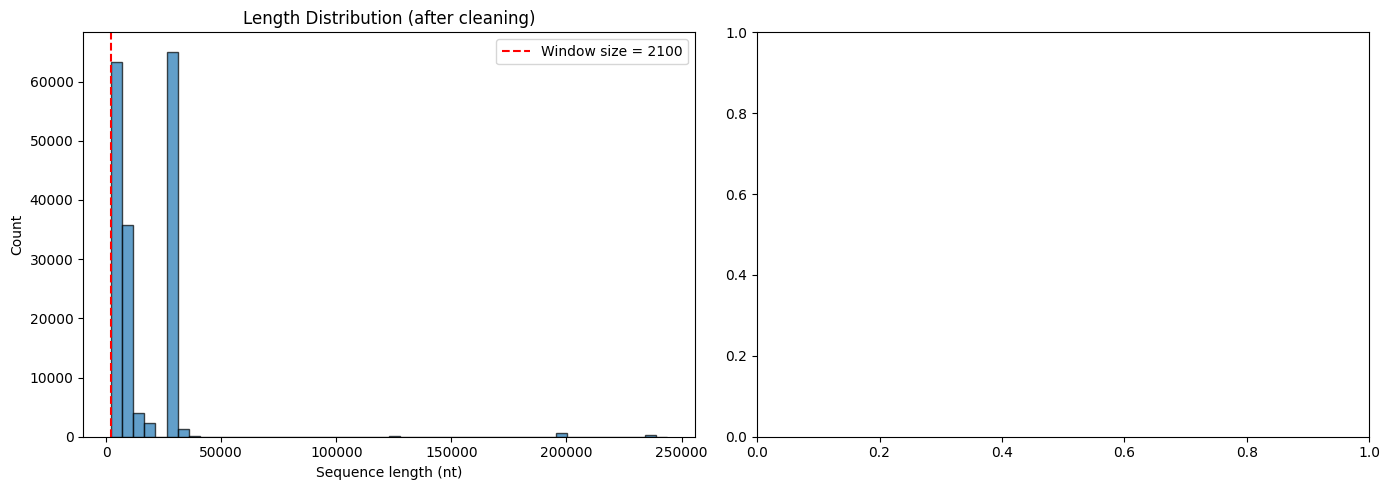

Plot saved to C:\Users\rodri\Desktop\MASTER\EMMBIOME\Grecia\Courses\Bioinformatics\Project\genomic_multimodal_fusion\data\processed/length_distribution.png


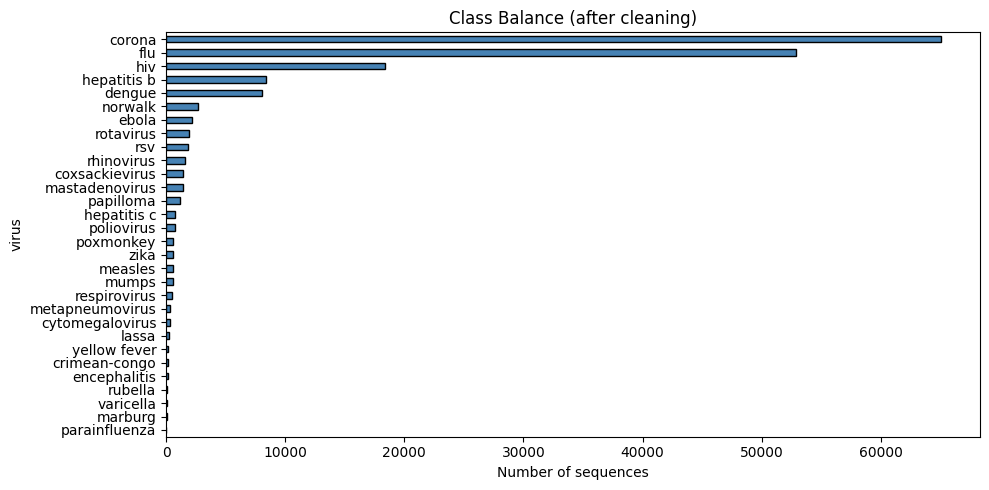


Splitting 172852 sequences (80/20 train/test) ...
  Train: 138281 sequences
  Test:  34571 sequences

  Class distribution (train):
virus
corona             52047
coxsackievirus      1127
crimean-congo        115
cytomegalovirus      249
dengue              6437
ebola               1748
encephalitis         106
flu                42276
hepatitis b         6709
hepatitis c          634
hiv                14685
lassa                210
marburg               46
mastadenovirus      1113
measles              459
metapneumovirus      284
mumps                439
norwalk             2149
papilloma            908
parainfluenza         26
poliovirus           577
poxmonkey            489
respirovirus         374
rhinovirus          1246
rotavirus           1572
rsv                 1468
rubella               85
varicella             57
yellow fever         165
zika                 481

Windowing train set:

Extracting windows (size=2100) ...
  Generated 1024117 windows from 138281 sequences

  

In [9]:

# ── Quick test ───────────────────────────────────────────────────
if __name__ == "__main__":
    # Load previously downloaded data
    # from src.data_loader import load_virus_dataset

    df_raw = pd.read_csv(PROCESSED_DIR / "all_viruses_sequences.csv")

    results = run_preprocessing_pipeline(df_raw, save=True)

    train_w = results["df_train_windows"]
    test_w  = results["df_test_windows"]

    print(f"\nFinal shapes:")
    print(f"  Train windows : {train_w.shape}")
    print(f"  Test windows  : {test_w.shape}")
    print(f"\nSample window:")
    print(train_w[["virus", "length", "label_enc"]].head(5))

In [ ]:
# ── Quick test ───────────────────────────────────────────────────
if __name__ == "__main__":
    df_raw = pd.read_csv(PROCESSED_DIR / "all_viruses_sequences.csv")

    results = run_preprocessing_pipeline(df_raw, save=True)

    train_w = results["df_train_windows"]
    test_w  = results["df_test_windows"]

    print(f"\nFinal shapes:")
    print(f"  Train windows : {train_w.shape}")
    print(f"  Test windows  : {test_w.shape}")
    print(f"\nSample window:")
    print(train_w[["virus", "length", "label_enc"]].head(5))